In [2]:

import os
import glob

DATASET_DIR = r"D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7"

print("Folder exists:", os.path.isdir(DATASET_DIR))

image_paths = glob.glob(
    os.path.join(DATASET_DIR, "s*", "*.pgm")
)

print("Images found:", len(image_paths))
print("First 5 images:")

for image_path in image_paths[:5]:
    print(image_path)


Folder exists: True
Images found: 400
First 5 images:
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\1.pgm
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\10.pgm
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\2.pgm
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\3.pgm
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\4.pgm


In [3]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)

print("All required libraries imported successfully.")

All required libraries imported successfully.


## Part A - Image Representation
• Read the face images as grayscale pixel matrices, inspect their dimensions and intensity values, flatten
each image into a feature vector, and create the complete image matrix with subject labels.
• Create a reproducible train-test split with images from every subject represented in both sets.

In [5]:
DATASET_DIR = (
    r"D:\Desktop\202618024_IreneStephen_DS605"
    r"\202618024_Lab_7"
)

assert os.path.isdir(DATASET_DIR), (
    f"Dataset folder not found: {DATASET_DIR}"
)

# Find PGM images inside subject folders.
image_paths = glob.glob(
    os.path.join(DATASET_DIR, "s*", "*.pgm")
)

# Sort first by subject number, then image number.
image_paths = sorted(
    image_paths,
    key=lambda p: (
        int(os.path.basename(os.path.dirname(p))[1:]),
        int(os.path.splitext(os.path.basename(p))[0])
    )
)

print("Dataset folder:", DATASET_DIR)
print("Total images found:", len(image_paths))
print("First five paths:")

for p in image_paths[:5]:
    print(p)

if len(image_paths) == 0:
    raise FileNotFoundError(
        "No .pgm images found inside the subject folders."
    )

Dataset folder: D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7
Total images found: 400
First five paths:
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\1.pgm
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\2.pgm
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\3.pgm
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\4.pgm
D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\s1\5.pgm


In [6]:
images_list = []
labels_list = []
image_numbers_list = []

for image_path in image_paths:
    # Subject folder name, e.g. s1, s2, ..., s40
    subject = os.path.basename(
        os.path.dirname(image_path)
    )

    image_number = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    with Image.open(image_path) as img:
        gray_image = img.convert("L")
        image_array = np.array(
            gray_image, dtype=np.uint8
        )

    images_list.append(image_array)
    labels_list.append(subject)
    image_numbers_list.append(image_number)

# Stack images into a 3D array.
images = np.stack(images_list)

y = np.array(labels_list)
image_numbers = np.array(image_numbers_list)

n_samples, image_height, image_width = images.shape
n_features = image_height * image_width

print("Images shape:", images.shape)
print("Number of images:", n_samples)
print("Number of subjects:", len(np.unique(y)))
print("Image height:", image_height)
print("Image width:", image_width)
print("Features per image:", n_features)
print("Minimum intensity:", images.min())
print("Maximum intensity:", images.max())
print("Data type:", images.dtype)

assert len(images) == len(y)
assert len(set(image.shape for image in images)) == 1

Images shape: (400, 112, 92)
Number of images: 400
Number of subjects: 40
Image height: 112
Image width: 92
Features per image: 10304
Minimum intensity: 0
Maximum intensity: 251
Data type: uint8


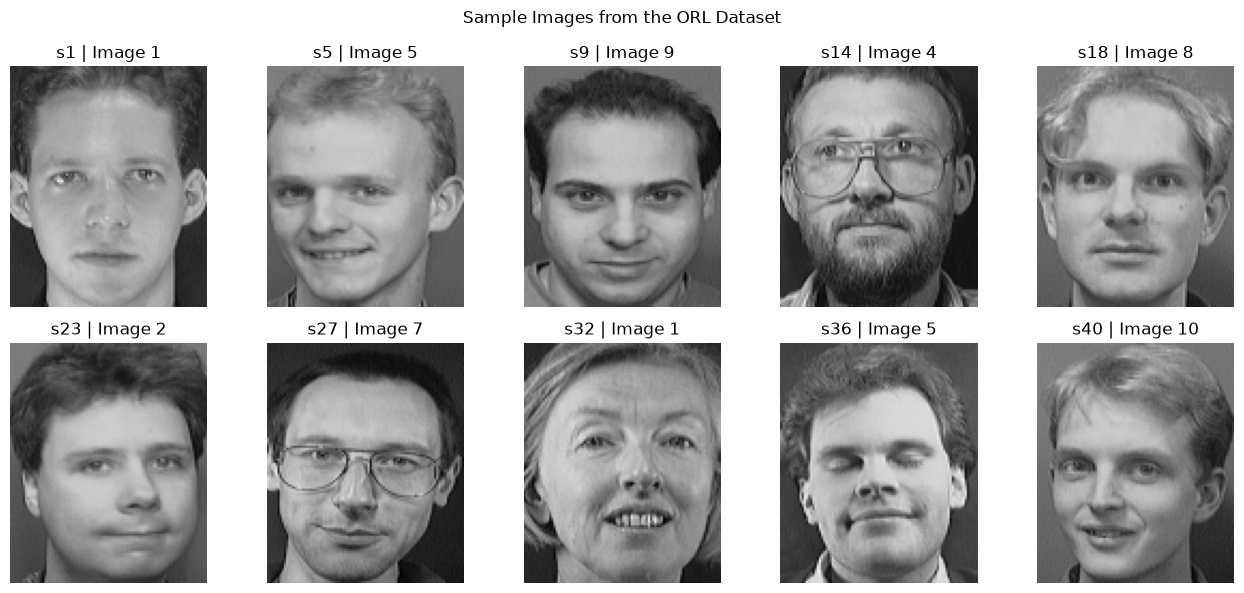

First image pixel matrix:
[[48 49 45 ... 56 56 54]
 [45 52 39 ... 52 50 51]
 [45 50 42 ... 48 53 50]
 ...
 [50 48 50 ... 45 46 46]
 [45 54 49 ... 46 47 47]
 [51 51 51 ... 47 46 46]]

First 20 pixel values:
[48 49 45 47 49 57 39 42 53 49 53 60 76 91 99 95 80 75 66 54]


In [7]:
fig, axes = plt.subplots(2, 5, figsize=(13, 6))

sample_indices = np.linspace(
    0, n_samples - 1, 10, dtype=int
)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{y[idx]} | Image {image_numbers[idx]}")
    ax.axis("off")

plt.suptitle("Sample Images from the ORL Dataset")
plt.tight_layout()
plt.show()

print("First image pixel matrix:")
print(images[0])

print("\nFirst 20 pixel values:")
print(images[0].flatten()[:20])

In [8]:
# Each image becomes one row of pixel features.
X = images.reshape(n_samples, n_features).astype(np.float64)

print("Flattened matrix shape:", X.shape)
print("Label array shape:", y.shape)

# Create a labeled DataFrame.
feature_columns = [
    f"pixel_{i}" for i in range(n_features)
]

image_df = pd.DataFrame(X, columns=feature_columns)
image_df.insert(0, "subject", y)
image_df.insert(1, "image_number", image_numbers)

display(image_df.iloc[:5, :12])

Flattened matrix shape: (400, 10304)
Label array shape: (400,)


,subject,image_number,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9
0,s1,1,48.0,49.0,45.0,47.0,49.0,57.0,39.0,42.0,53.0,49.0
1,s1,2,60.0,60.0,62.0,53.0,48.0,51.0,61.0,60.0,71.0,68.0
2,s1,3,39.0,44.0,53.0,37.0,61.0,48.0,61.0,45.0,35.0,40.0
3,s1,4,63.0,53.0,35.0,36.0,33.0,34.0,31.0,35.0,39.0,43.0
4,s1,5,64.0,76.0,80.0,53.0,34.0,72.0,60.0,66.0,66.0,50.0


In [9]:
all_indices = np.arange(n_samples)

train_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

images_train = images[train_idx]
images_test = images[test_idx]

paths_train = np.array(image_paths, dtype=object)[train_idx]
paths_test = np.array(image_paths, dtype=object)[test_idx]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training subjects:", len(np.unique(y_train)))
print("Testing subjects:", len(np.unique(y_test)))

split_df = pd.DataFrame({
    "Train images": pd.Series(y_train).value_counts(),
    "Test images": pd.Series(y_test).value_counts()
}).sort_index()

display(split_df)

assert set(y_train) == set(y)
assert set(y_test) == set(y)

Training shape: (320, 10304)
Testing shape: (80, 10304)
Training subjects: 40
Testing subjects: 40


,Train images,Test images
s1,8,2
s10,8,2
s11,8,2
s12,8,2
s13,8,2
s14,8,2
s15,8,2
s16,8,2
s17,8,2
s18,8,2


## Part B - PCA, Eigenfaces and Compression
• Compute the mean face and center the training data. Use covariance/eigendecomposition and SVD to
obtain the principal directions and compare the two approaches.
• Plot cumulative explained variance and retain the minimum number of components needed to preserve at
least 90% variance. Reshape selected principal components back into images to visualize eigenfaces.
• Project faces into PCA space, store the reduced representation, reconstruct sample faces, and compare
reconstruction quality and storage with the original pixel representation.

Mean face shape: (10304,)
Centered training shape: (320, 10304)
Centered test shape: (80, 10304)


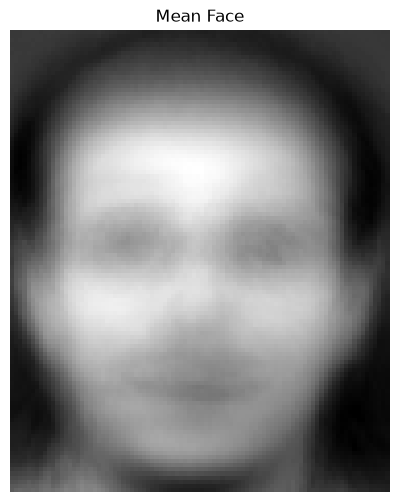

In [10]:
mean_face = np.mean(X_train, axis=0)

X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

mean_face_image = mean_face.reshape(
    image_height, image_width
)

print("Mean face shape:", mean_face.shape)
print("Centered training shape:", X_train_centered.shape)
print("Centered test shape:", X_test_centered.shape)

plt.figure(figsize=(5, 6))
plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

In [11]:
n_train = X_train_centered.shape[0]

# Sample-space covariance matrix.
C = (X_train_centered @ X_train_centered.T) / (n_train - 1)

# Eigenvalue decomposition of the symmetric covariance matrix.
eigvals_cov, eigvecs_cov = np.linalg.eigh(C)

# Sort eigenvalues in descending order.
order = np.argsort(eigvals_cov)[::-1]
eigvals_cov = eigvals_cov[order]
eigvecs_cov = eigvecs_cov[:, order]

# Remove small or zero eigenvalues caused by numerical precision.
tol_cov = (
    np.finfo(float).eps
    * max(C.shape)
    * max(eigvals_cov[0], 1.0)
)

valid_cov = eigvals_cov > tol_cov

eigvals_cov = eigvals_cov[valid_cov]
eigvecs_cov = eigvecs_cov[:, valid_cov]

# Convert sample-space eigenvectors to pixel-space eigenfaces.
components_cov = (
    X_train_centered.T @ eigvecs_cov
) / np.sqrt(
    (n_train - 1) * eigvals_cov
)[None, :]

# Normalize the principal directions.
components_cov /= np.linalg.norm(
    components_cov, axis=0, keepdims=True
)

print("Covariance matrix shape:", C.shape)
print("Covariance PCA components:", components_cov.shape)
print("First 10 eigenvalues:")
print(eigvals_cov[:10])

Covariance matrix shape: (320, 320)
Covariance PCA components: (10304, 319)
First 10 eigenvalues:
[2816908.9049542  2065888.08037511 1106610.56261326  910139.72828772
  840787.5711825   532737.77224155  402438.73402672  369949.59846512
  327580.19253175  289612.4509677 ]


In [12]:
U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

eigvals_svd_all = singular_values**2 / (n_train - 1)

tol_svd = (
    np.finfo(float).eps
    * max(X_train_centered.shape)
    * max(singular_values[0], 1.0)
)

valid_svd = singular_values > tol_svd

singular_values = singular_values[valid_svd]
eigvals_svd = eigvals_svd_all[valid_svd]

# Each column is a principal direction in pixel space.
components_svd = Vt[valid_svd].T

print("U shape:", U.shape)
print("Vt shape:", Vt.shape)
print("SVD components shape:", components_svd.shape)
print("First 10 SVD eigenvalues:")
print(eigvals_svd[:10])

U shape: (320, 320)
Vt shape: (320, 10304)
SVD components shape: (10304, 319)
First 10 SVD eigenvalues:
[2816908.9049542  2065888.0803751  1106610.56261326  910139.72828772
  840787.5711825   532737.77224154  402438.73402672  369949.59846512
  327580.19253175  289612.4509677 ]


,Component,Covariance eigenvalue,SVD eigenvalue,Absolute alignment
0,1,2.816909e+06,2.816909e+06,1.0
1,2,2.065888e+06,2.065888e+06,1.0
2,3,1.106611e+06,1.106611e+06,1.0
3,4,9.101397e+05,9.101397e+05,1.0
4,5,8.407876e+05,8.407876e+05,1.0
5,6,5.327378e+05,5.327378e+05,1.0
6,7,4.024387e+05,4.024387e+05,1.0
7,8,3.699496e+05,3.699496e+05,1.0
8,9,3.275802e+05,3.275802e+05,1.0
9,10,2.896125e+05,2.896125e+05,1.0


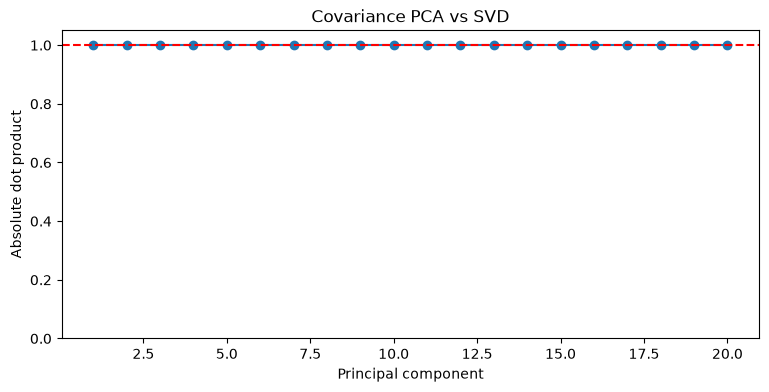

In [13]:
n_compare = min(
    20,
    components_cov.shape[1],
    components_svd.shape[1]
)

alignment = np.abs(np.sum(
    components_cov[:, :n_compare]
    * components_svd[:, :n_compare],
    axis=0
))

comparison_df = pd.DataFrame({
    "Component": np.arange(1, n_compare + 1),
    "Covariance eigenvalue": eigvals_cov[:n_compare],
    "SVD eigenvalue": eigvals_svd[:n_compare],
    "Absolute alignment": alignment
})

display(comparison_df)

plt.figure(figsize=(9, 4))
plt.plot(
    np.arange(1, n_compare + 1),
    alignment,
    marker="o"
)
plt.axhline(1.0, color="red", linestyle="--")
plt.xlabel("Principal component")
plt.ylabel("Absolute dot product")
plt.title("Covariance PCA vs SVD")
plt.ylim(0, 1.05)
plt.show()

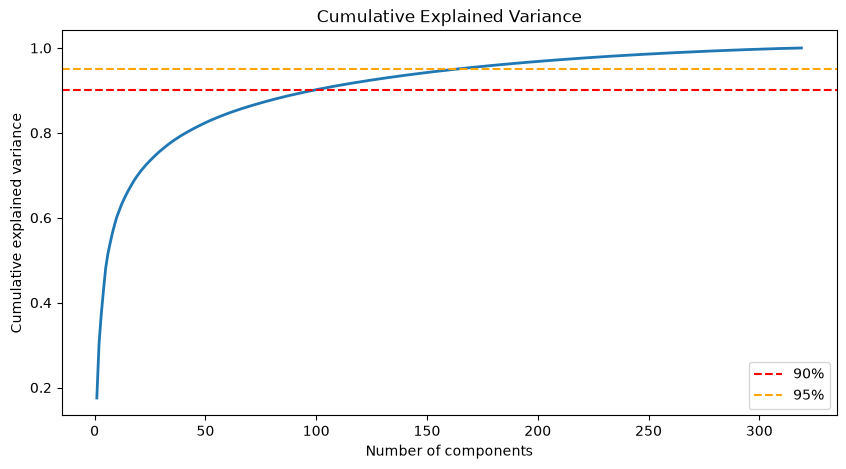

Components for 90% variance: 99
Components for 95% variance: 163
Variance retained at k_90: 90.07%


In [14]:
explained_variance_ratio = eigvals_svd / eigvals_svd.sum()
cumulative_variance = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(10, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)

plt.axhline(0.90, color="red", linestyle="--", label="90%")
plt.axhline(0.95, color="orange", linestyle="--", label="95%")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.show()

k_90 = np.searchsorted(cumulative_variance, 0.90) + 1
k_95 = np.searchsorted(cumulative_variance, 0.95) + 1

print("Components for 90% variance:", k_90)
print("Components for 95% variance:", k_95)
print("Variance retained at k_90:",
      f"{cumulative_variance[k_90 - 1]:.2%}")

Selected components: 99
Component matrix: (10304, 99)


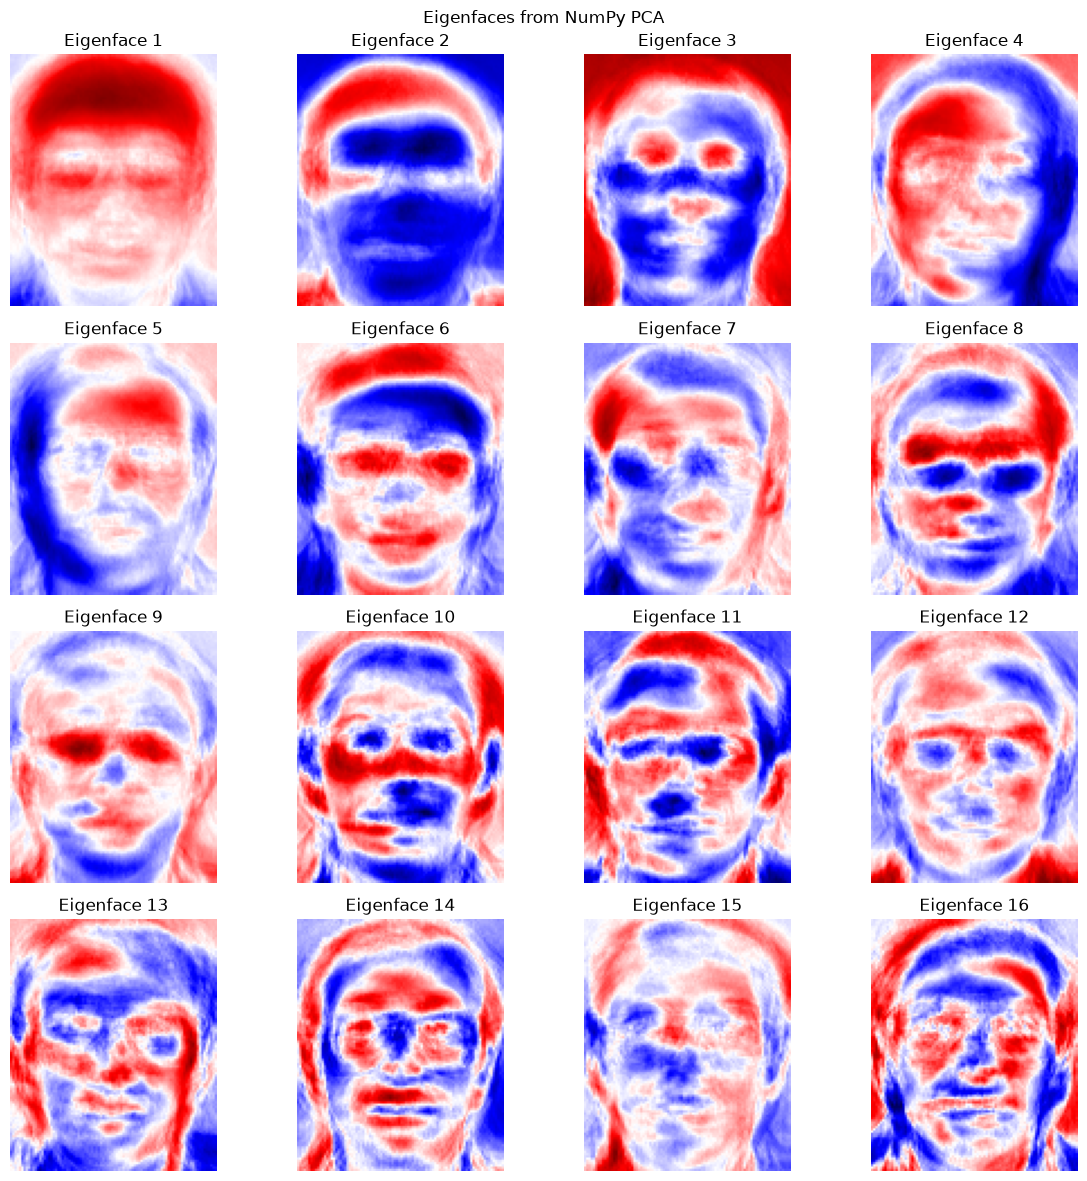

In [15]:
n_components = k_90

components = components_svd[:, :n_components]

print("Selected components:", n_components)
print("Component matrix:", components.shape)

n_show = min(16, n_components)
fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i, ax in enumerate(axes.flat):
    if i < n_show:
        eigenface = components[:, i].reshape(
            image_height, image_width
        )

        limit = np.max(np.abs(eigenface))

        ax.imshow(
            eigenface,
            cmap="seismic",
            vmin=-limit,
            vmax=limit
        )
        ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("Eigenfaces from NumPy PCA")
plt.tight_layout()
plt.show()

In [16]:
Z_train = X_train_centered @ components
Z_test = X_test_centered @ components

print("Reduced training matrix:", Z_train.shape)
print("Reduced test matrix:", Z_test.shape)

pca_columns = [
    f"PC{i + 1}" for i in range(n_components)
]

Z_train_df = pd.DataFrame(Z_train, columns=pca_columns)
Z_train_df.insert(0, "subject", y_train)

Z_test_df = pd.DataFrame(Z_test, columns=pca_columns)
Z_test_df.insert(0, "subject", y_test)

display(Z_train_df.head())
display(Z_test_df.head())

Reduced training matrix: (320, 99)
Reduced test matrix: (80, 99)


,subject,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,...,PC90,PC91,PC92,PC93,PC94,PC95,PC96,PC97,PC98,PC99
0,s21,-1767.091085,-440.930189,806.683765,-446.257447,719.873702,-103.883523,730.337368,-334.359310,87.636984,...,-154.211703,1.549561,83.981241,-68.521959,22.092201,9.667427,-120.863516,131.741422,-36.328105,21.609195
1,s14,29.327553,2101.674032,-867.388154,1516.614344,1749.392094,-159.047198,-155.358019,3.863982,791.999161,...,278.001937,169.913846,-6.713805,-293.875389,226.764029,-129.727761,233.784406,253.560791,-239.829913,-47.600801
2,s12,1096.933539,-573.518116,617.997982,838.039152,538.933540,-73.186028,1368.130017,1574.875517,-1179.635490,...,-70.953707,125.240828,102.858863,292.412306,117.326328,-283.704683,230.635152,-111.114008,-72.987774,-110.179269
3,s20,-1273.881613,-1539.389369,-732.591217,-684.204402,1739.440901,-717.332288,-468.894285,-1226.219036,-34.003612,...,130.769016,-94.325953,-4.655024,1.663090,-66.542703,78.415439,-25.706373,-199.133609,58.619371,366.245756
4,s19,1714.114476,1574.999731,-1022.325902,792.560330,-729.949661,-403.001988,382.548540,-426.280987,491.065855,...,-76.198397,195.623918,118.921859,36.862144,116.879612,27.014074,-45.826469,-47.581710,-63.994200,248.994360


,subject,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,...,PC90,PC91,PC92,PC93,PC94,PC95,PC96,PC97,PC98,PC99
0,s10,-2218.058379,-1526.274291,-778.895905,753.723786,537.048893,1117.990717,95.277284,1312.391075,-357.523610,...,-56.130649,10.832659,4.570721,135.564137,82.338124,52.917410,23.370942,-141.499866,-67.989292,66.269636
1,s5,1100.584652,-837.789360,1548.514107,532.599221,-902.062828,-213.582603,-85.384886,765.210335,-518.591812,...,-19.741812,-59.554729,-66.330825,111.634387,-19.895426,2.974134,68.370240,55.152638,-100.336697,-2.562090
2,s26,1465.163349,88.036329,1507.024969,86.652726,1547.648286,-638.684371,382.024750,637.596515,469.813316,...,-28.757595,78.878203,84.569225,14.130211,-22.941814,-139.789531,76.226954,-10.507675,8.562937,-74.596220
3,s24,-479.585383,281.257239,-1745.351366,-1235.605286,-796.106040,510.908857,69.075055,-671.786409,-682.328305,...,-34.746313,-81.953633,-3.506860,65.559046,102.627566,-66.247787,61.620201,127.396852,-16.939922,-65.619093
4,s9,-1296.828386,-827.610559,519.092875,333.406364,488.023840,-893.162045,-93.179616,1160.100951,546.207956,...,-63.559754,-29.777868,30.466149,72.679294,-56.900164,144.029442,85.335501,95.383993,-116.893929,123.439497


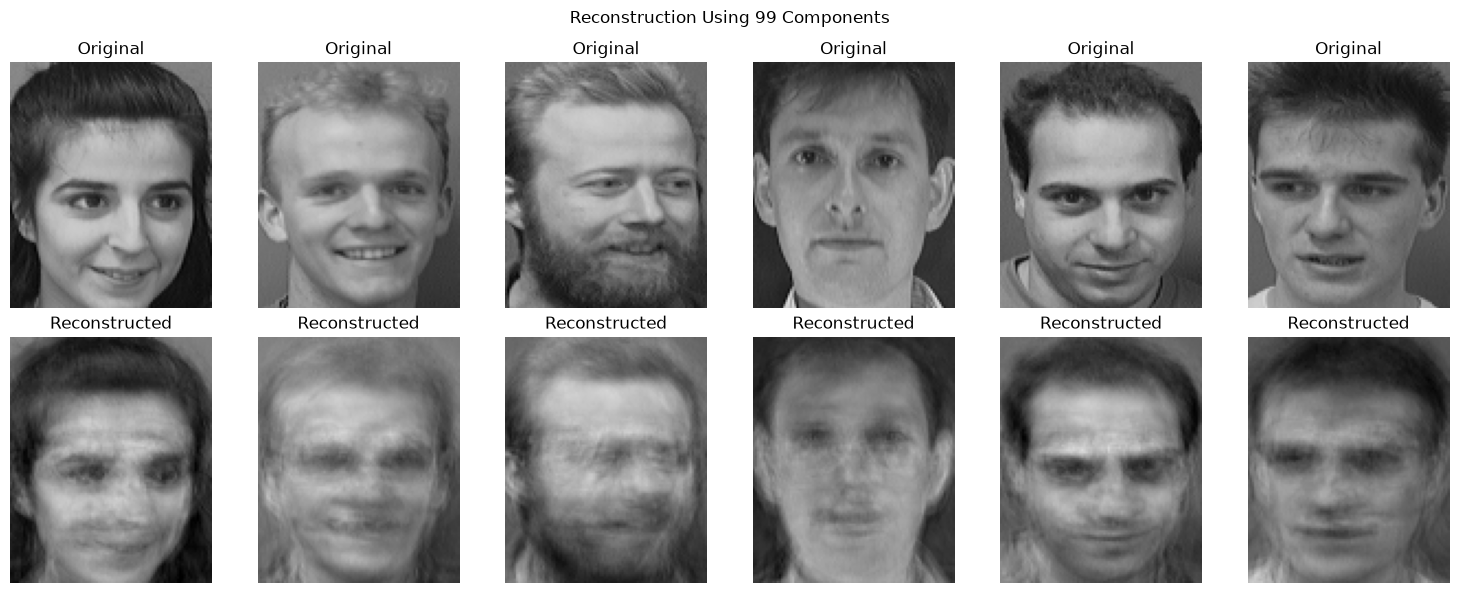

In [17]:
def reconstruct_faces(Z, mean_vector, principal_components):
    return Z @ principal_components.T + mean_vector


X_test_reconstructed = reconstruct_faces(
    Z_test,
    mean_face,
    components
)

n_show = min(6, len(X_test))

fig, axes = plt.subplots(2, n_show, figsize=(15, 6))

for i in range(n_show):
    axes[0, i].imshow(
        images_test[i], cmap="gray", vmin=0, vmax=255
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    reconstructed = X_test_reconstructed[i].reshape(
        image_height, image_width
    )

    axes[1, i].imshow(
        np.clip(reconstructed, 0, 255),
        cmap="gray", vmin=0, vmax=255
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.suptitle(f"Reconstruction Using {n_components} Components")
plt.tight_layout()
plt.show()

In [18]:
def calculate_metrics(original, reconstructed):
    mse = np.mean((original - reconstructed) ** 2)
    rmse = np.sqrt(mse)
    psnr = np.inf if mse == 0 else 20 * np.log10(255 / rmse)
    return mse, rmse, psnr


reconstruction_results = []

for k in sorted(set([
    min(10, n_components),
    min(25, n_components),
    min(50, n_components),
    n_components
])):
    current_components = components_svd[:, :k]

    Z = X_test_centered @ current_components

    reconstructed = reconstruct_faces(
        Z, mean_face, current_components
    )

    mse, rmse, psnr = calculate_metrics(
        X_test, reconstructed
    )

    reconstruction_results.append({
        "Components": k,
        "Variance retained": cumulative_variance[k - 1],
        "MSE": mse,
        "RMSE": rmse,
        "PSNR (dB)": psnr
    })

reconstruction_df = pd.DataFrame(reconstruction_results)
display(reconstruction_df.round(4))

,Components,Variance retained,MSE,RMSE,PSNR (dB)
0,10,0.6018,654.5500,25.5842,19.9714
1,25,0.7347,485.9994,22.0454,21.2644
2,50,0.8240,388.9957,19.7230,22.2314
3,99,0.9007,321.3613,17.9266,23.0609


In [19]:
original_values = n_samples * n_features

# Scores for all images using the PCA model fitted on training data.
Z_all = (X - mean_face) @ components

score_values = n_samples * n_components
basis_values = n_features * (n_components + 1)

total_pca_values = score_values + basis_values

storage_df = pd.DataFrame({
    "Representation": [
        "Original pixels",
        "PCA scores only",
        "PCA scores + mean + basis"
    ],
    "Numeric values": [
        original_values,
        score_values,
        total_pca_values
    ]
})

storage_df["Storage in MiB (float64)"] = (
    storage_df["Numeric values"] * 8 / (1024 ** 2)
)

display(storage_df)

print(
    "Storage reduction including basis:",
    f"{100 * (1 - total_pca_values / original_values):.2f}%"
)

,Representation,Numeric values,Storage in MiB (float64)
0,Original pixels,4121600,31.445312
1,PCA scores only,39600,0.302124
2,PCA scores + mean + basis,1070000,8.163452


Storage reduction including basis: 74.04%


## Part C - Recognition in PCA Space
• For each test image, generate its PCA representation and identify the closest stored training face using a
suitable distance measure such as Euclidean distance.
• Report recognition accuracy, inspect a few correct and incorrect matches, and compare recognition using
raw pixels with recognition using the reduced PCA representation.

In [20]:
def nearest_neighbor_predict(
    X_reference, y_reference, X_query, batch_size=64
):
    predictions = []
    nearest_indices = []
    nearest_distances = []

    reference_squared = np.sum(
        X_reference ** 2, axis=1
    )

    for start in range(0, len(X_query), batch_size):
        query = X_query[start:start + batch_size]

        distances_squared = (
            np.sum(query ** 2, axis=1)[:, None]
            + reference_squared[None, :]
            - 2 * query @ X_reference.T
        )

        distances = np.sqrt(
            np.maximum(distances_squared, 0.0)
        )

        nearest = np.argmin(distances, axis=1)

        predictions.extend(y_reference[nearest])
        nearest_indices.extend(nearest)
        nearest_distances.extend(
            distances[np.arange(len(nearest)), nearest]
        )

    return (
        np.asarray(predictions),
        np.asarray(nearest_indices),
        np.asarray(nearest_distances)
    )


y_pred_pca, nn_indices_pca, nn_distances_pca = (
    nearest_neighbor_predict(Z_train, y_train, Z_test)
)

accuracy_pca_nn = accuracy_score(y_test, y_pred_pca)

print("PCA nearest-neighbor accuracy:",
      f"{accuracy_pca_nn:.2%}")
print("Correct predictions:",
      f"{np.sum(y_test == y_pred_pca)} / {len(y_test)}")

PCA nearest-neighbor accuracy: 98.75%
Correct predictions: 79 / 80


,Method,Features,Accuracy
0,Raw pixel nearest neighbor,10304,0.9875
1,PCA nearest neighbor,99,0.9875


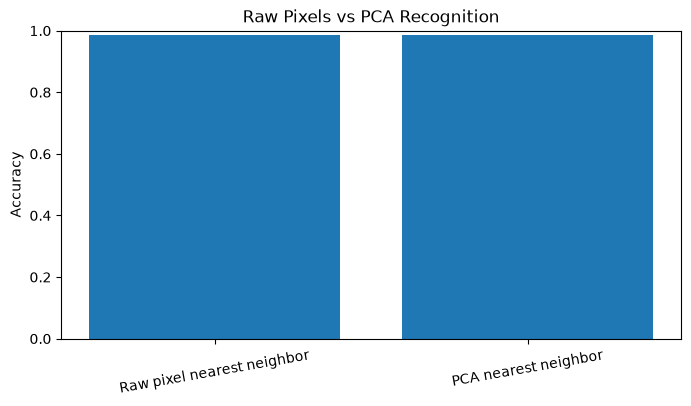

In [21]:
y_pred_raw, nn_indices_raw, nn_distances_raw = (
    nearest_neighbor_predict(X_train, y_train, X_test)
)

accuracy_raw_nn = accuracy_score(y_test, y_pred_raw)

nn_results = pd.DataFrame({
    "Method": [
        "Raw pixel nearest neighbor",
        "PCA nearest neighbor"
    ],
    "Features": [
        n_features,
        n_components
    ],
    "Accuracy": [
        accuracy_raw_nn,
        accuracy_pca_nn
    ]
})

display(nn_results)

plt.figure(figsize=(8, 4))
plt.bar(nn_results["Method"], nn_results["Accuracy"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Raw Pixels vs PCA Recognition")
plt.xticks(rotation=10)
plt.show()

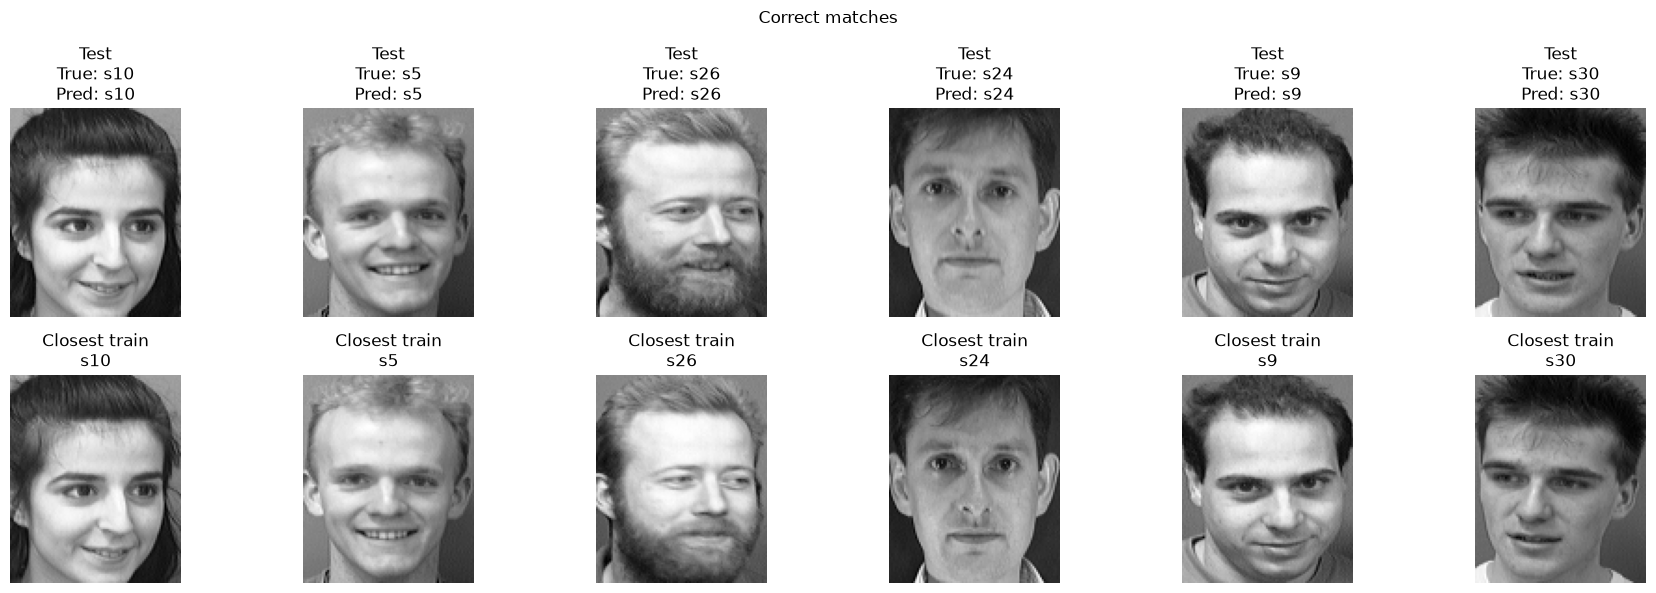

In [22]:
def display_matches(correct=True, max_examples=6):
    condition = (
        y_test == y_pred_pca
        if correct
        else y_test != y_pred_pca
    )

    selected = np.flatnonzero(condition)[:max_examples]

    if len(selected) == 0:
        print("No examples in this category.")
        return

    fig, axes = plt.subplots(
        2, len(selected),
        figsize=(3 * len(selected), 6),
        squeeze=False
    )

    for col, test_i in enumerate(selected):
        train_i = nn_indices_pca[test_i]

        axes[0, col].imshow(images_test[test_i], cmap="gray")
        axes[0, col].set_title(
            f"Test\nTrue: {y_test[test_i]}\n"
            f"Pred: {y_pred_pca[test_i]}"
        )

        axes[1, col].imshow(images_train[train_i], cmap="gray")
        axes[1, col].set_title(
            f"Closest train\n{y_train[train_i]}"
        )

        axes[0, col].axis("off")
        axes[1, col].axis("off")

    plt.suptitle(
        "Correct matches" if correct else "Incorrect matches"
    )
    plt.tight_layout()
    plt.show()


display_matches(correct=True)

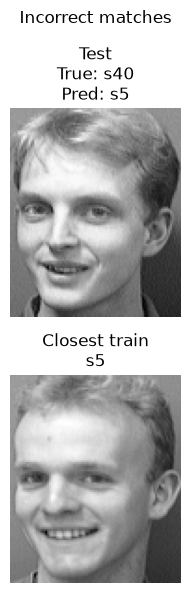

In [23]:
display_matches(correct=False)


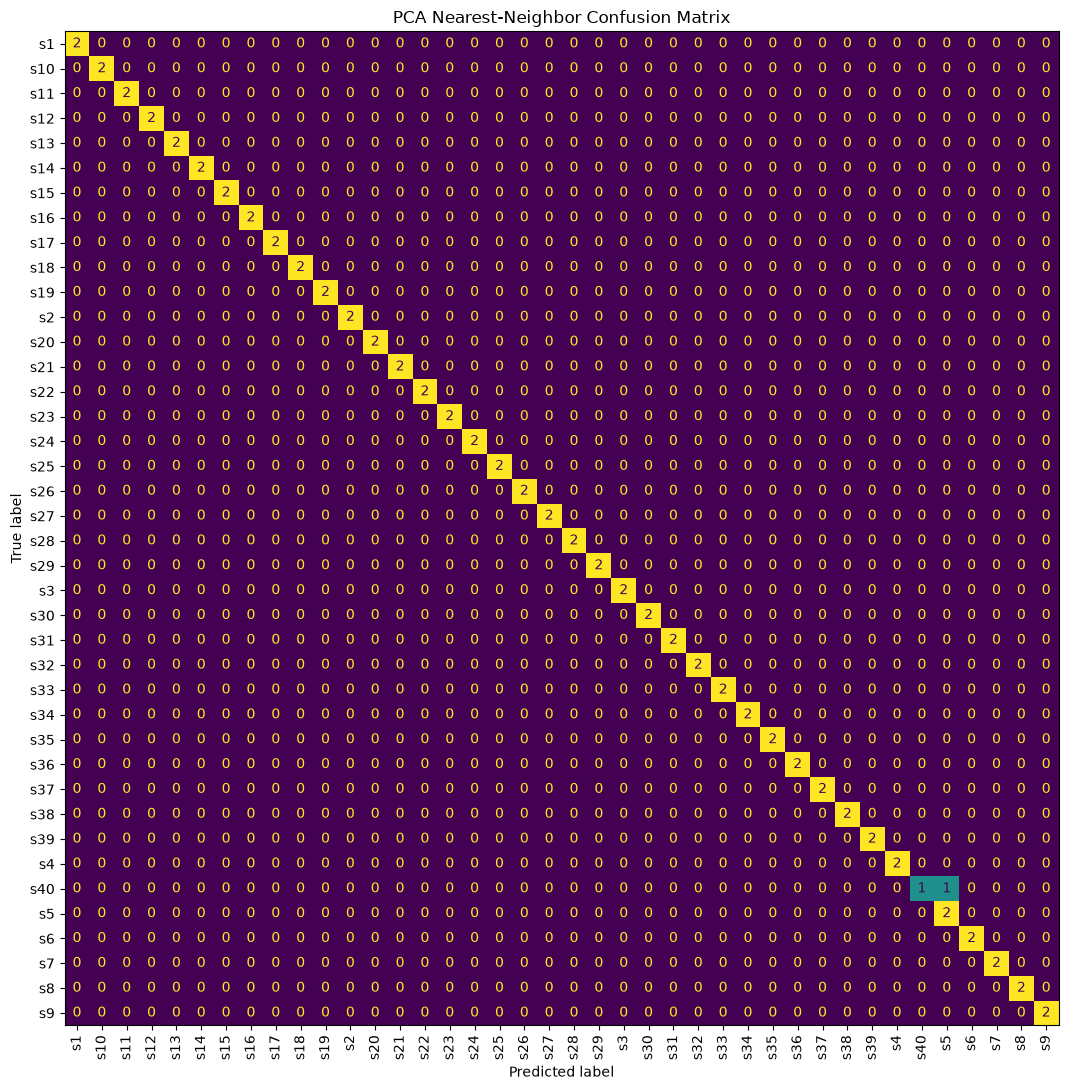

In [24]:
subject_order = sorted(np.unique(y))

cm = confusion_matrix(
    y_test, y_pred_pca, labels=subject_order
)

fig, ax = plt.subplots(figsize=(13, 11))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=subject_order
)

disp.plot(ax=ax, xticks_rotation=90, colorbar=False)
plt.title("PCA Nearest-Neighbor Confusion Matrix")
plt.tight_layout()
plt.show()

## Part D - Traditional Machine Learning
• Use the PCA features to train at least two traditional classifiers such as KNN, Logistic Regression, or
SVM, and compare them with the similarity-based baseline.
• Experiment with the number of retained components and suitable model settings to improve recognition
while keeping the representation compact.

In [25]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

Classes: ['s1' 's10' 's11' 's12' 's13' 's14' 's15' 's16' 's17' 's18' 's19' 's2'
 's20' 's21' 's22' 's23' 's24' 's25' 's26' 's27' 's28' 's29' 's3' 's30'
 's31' 's32' 's33' 's34' 's35' 's36' 's37' 's38' 's39' 's4' 's40' 's5'
 's6' 's7' 's8' 's9']


In [26]:
models = {
    "KNN": KNeighborsClassifier(
        n_neighbors=3,
        weights="distance"
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            C=1.0,
            random_state=SEED
        )
    ),

    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=10.0,
            gamma="scale"
        )
    )
}

model_predictions = {}
model_results = []

for name, model in models.items():
    model.fit(Z_train, y_train_encoded)

    predictions_encoded = model.predict(Z_test)

    predictions = label_encoder.inverse_transform(
        predictions_encoded
    )

    model_predictions[name] = predictions

    accuracy = accuracy_score(y_test, predictions)

    model_results.append({
        "Method": name,
        "Components": n_components,
        "Accuracy": accuracy
    })

    print(f"{name}: {accuracy:.2%}")

KNN: 98.75%
Logistic Regression: 96.25%
SVM (RBF): 95.00%


,Method,Components,Accuracy
0,Raw pixel nearest neighbor,10304,98.75%
1,PCA nearest neighbor,99,98.75%
2,KNN,99,98.75%
3,Logistic Regression,99,96.25%
4,SVM (RBF),99,95.00%


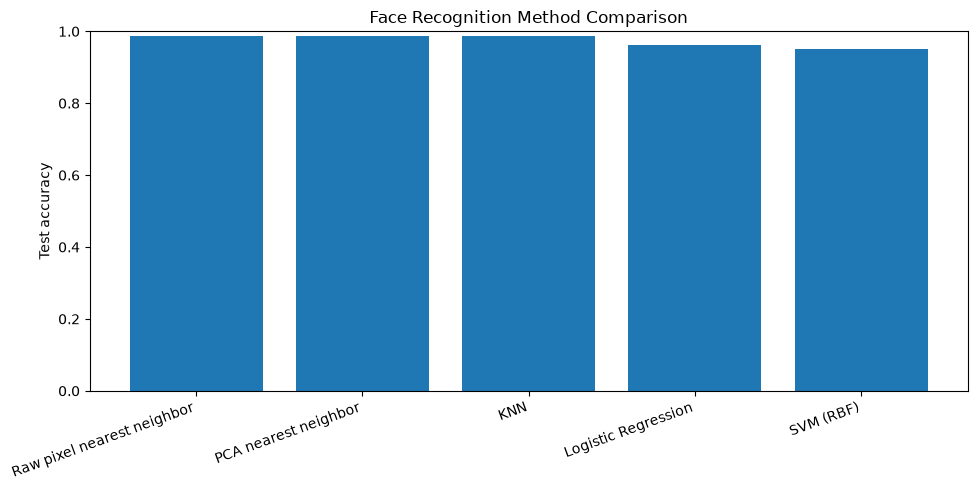

In [27]:
final_results = pd.DataFrame([
    {
        "Method": "Raw pixel nearest neighbor",
        "Components": n_features,
        "Accuracy": accuracy_raw_nn
    },
    {
        "Method": "PCA nearest neighbor",
        "Components": n_components,
        "Accuracy": accuracy_pca_nn
    },
    *model_results
])

final_results = final_results.sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)

display(final_results.style.format({
    "Accuracy": "{:.2%}"
}))

plt.figure(figsize=(10, 5))
plt.bar(final_results["Method"], final_results["Accuracy"])
plt.ylim(0, 1)
plt.ylabel("Test accuracy")
plt.title("Face Recognition Method Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [28]:
best_model_name = max(
    model_predictions,
    key=lambda name: accuracy_score(
        y_test, model_predictions[name]
    )
)

print("Best traditional classifier:", best_model_name)

print(classification_report(
    y_test,
    model_predictions[best_model_name],
    labels=subject_order,
    zero_division=0
))

Best traditional classifier: KNN
              precision    recall  f1-score   support

          s1       1.00      1.00      1.00         2
         s10       1.00      1.00      1.00         2
         s11       1.00      1.00      1.00         2
         s12       1.00      1.00      1.00         2
         s13       1.00      1.00      1.00         2
         s14       1.00      1.00      1.00         2
         s15       1.00      1.00      1.00         2
         s16       1.00      1.00      1.00         2
         s17       1.00      1.00      1.00         2
         s18       1.00      1.00      1.00         2
         s19       1.00      1.00      1.00         2
          s2       1.00      1.00      1.00         2
         s20       1.00      1.00      1.00         2
         s21       1.00      1.00      1.00         2
         s22       1.00      1.00      1.00         2
         s23       1.00      1.00      1.00         2
         s24       1.00      1.00      1.00     

In [29]:
candidate_components = sorted(set(
    k for k in [
        10, 20, 30, 40, 50, 75, 100, 150, k_90
    ]
    if 1 <= k <= components_svd.shape[1]
))

tuning_results = []

for k in candidate_components:
    current_components = components_svd[:, :k]

    Ztr = X_train_centered @ current_components
    Zte = X_test_centered @ current_components

    # PCA nearest neighbor.
    pred, _, _ = nearest_neighbor_predict(
        Ztr, y_train, Zte
    )

    tuning_results.append({
        "Components": k,
        "Method": "PCA nearest neighbor",
        "Accuracy": accuracy_score(y_test, pred)
    })

    # KNN.
    knn = KNeighborsClassifier(
        n_neighbors=3,
        weights="distance"
    )
    knn.fit(Ztr, y_train_encoded)

    pred = label_encoder.inverse_transform(knn.predict(Zte))

    tuning_results.append({
        "Components": k,
        "Method": "KNN",
        "Accuracy": accuracy_score(y_test, pred)
    })

    # Logistic Regression.
    lr = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        )
    )
    lr.fit(Ztr, y_train_encoded)

    pred = label_encoder.inverse_transform(lr.predict(Zte))

    tuning_results.append({
        "Components": k,
        "Method": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, pred)
    })

    # SVM.
    svm = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10, gamma="scale")
    )
    svm.fit(Ztr, y_train_encoded)

    pred = label_encoder.inverse_transform(svm.predict(Zte))

    tuning_results.append({
        "Components": k,
        "Method": "SVM (RBF)",
        "Accuracy": accuracy_score(y_test, pred)
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.pivot(
    index="Components",
    columns="Method",
    values="Accuracy"
).style.format("{:.2%}"))

Method,KNN,Logistic Regression,PCA nearest neighbor,SVM (RBF)
Components,,,,
10,96.25%,91.25%,97.50%,96.25%
20,97.50%,93.75%,98.75%,98.75%
30,97.50%,95.00%,100.00%,97.50%
40,98.75%,96.25%,100.00%,97.50%
50,98.75%,97.50%,98.75%,97.50%
75,98.75%,97.50%,98.75%,97.50%
99,98.75%,96.25%,98.75%,95.00%
100,98.75%,96.25%,98.75%,95.00%
150,98.75%,95.00%,98.75%,91.25%


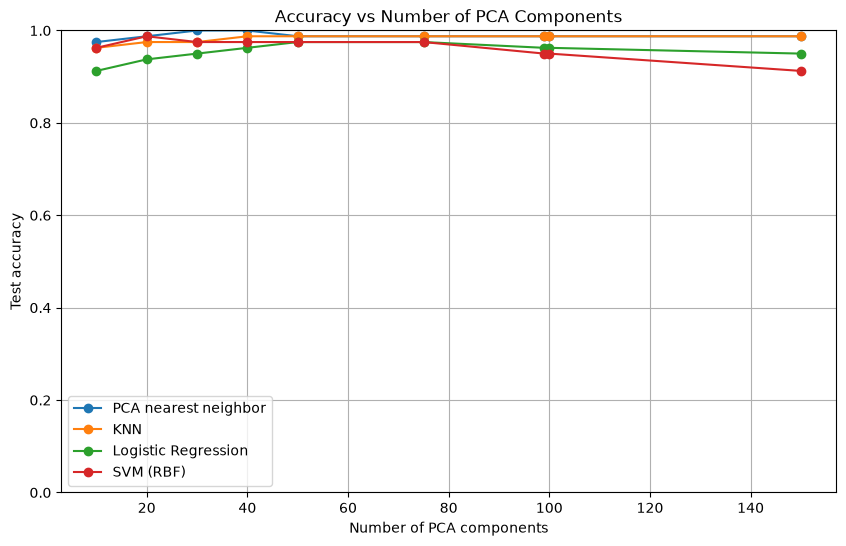

Best observed configuration:
Components                      30
Method        PCA nearest neighbor
Accuracy                       1.0
Name: 8, dtype: object


In [30]:
plt.figure(figsize=(10, 6))

for method in tuning_df["Method"].unique():
    subset = tuning_df[tuning_df["Method"] == method]

    plt.plot(
        subset["Components"],
        subset["Accuracy"],
        marker="o",
        label=method
    )

plt.xlabel("Number of PCA components")
plt.ylabel("Test accuracy")
plt.title("Accuracy vs Number of PCA Components")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

best_configuration = tuning_df.loc[
    tuning_df["Accuracy"].idxmax()
]

print("Best observed configuration:")
print(best_configuration)

In [31]:
OUTPUT_DIR = os.path.join(DATASET_DIR, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

final_results.to_csv(
    os.path.join(OUTPUT_DIR, "final_results.csv"),
    index=False
)

tuning_df.to_csv(
    os.path.join(OUTPUT_DIR, "component_tuning_results.csv"),
    index=False
)

reconstruction_df.to_csv(
    os.path.join(OUTPUT_DIR, "reconstruction_results.csv"),
    index=False
)

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "pca_representations.npz"),
    Z_train=Z_train,
    Z_test=Z_test,
    y_train=y_train,
    y_test=y_test,
    mean_face=mean_face,
    components=components,
    explained_variance_ratio=explained_variance_ratio
)

print("All results saved to:", OUTPUT_DIR)
print("\nFinal accuracy summary:")
display(final_results)

All results saved to: D:\Desktop\202618024_IreneStephen_DS605\202618024_Lab_7\outputs

Final accuracy summary:


,Method,Components,Accuracy
0,Raw pixel nearest neighbor,10304,0.9875
1,PCA nearest neighbor,99,0.9875
2,KNN,99,0.9875
3,Logistic Regression,99,0.9625
4,SVM (RBF),99,0.9500
